# Analítica de scrap y costo de no calidad (COPQ)
**Planta ficticia de autopartes · 3 líneas · año 2025**

> **Datos sintéticos.** Se generaron con `scrap_copq/generate.py` (semilla fija) e imitan problemas típicos de planta. Ninguna cifra corresponde a una empresa real.

## Resumen ejecutivo

**La no calidad costó 8.5 millones de MXN en 2025 (1.9 % de las ventas). Tres palancas recortan alrededor de 1.2 millones al año, y una sola concentra más del 80 % del ahorro: ajustar el mantenimiento preventivo de la línea robotizada.**

1. **El desgaste entre mantenimientos de L2 es la mayor fuga.** L2 genera el 49 % del costo de scrap. Su tasa se mantiene cerca de 1.9 % hasta unas 170 horas desde el mantenimiento y llega a 6 % a las 310 horas; el intervalo actual es de 320 horas.
2. **El volumen engaña.** La *falta de fusión* es apenas el 5 % de las piezas desechadas pero el 16 % del costo: destruye piezas soldadas caras y originó 6 de los 8 reclamos de cliente.
3. **El problema del turno nocturno es la rotación.** Las 10 altas del año entraron al turno nocturno, y cada operador nuevo en soldadura manual eleva cerca de un 34 % la probabilidad de scrap.

El detalle por palanca está en la sección 7.

**Contenido:** 1. Calidad de datos · 2. Costo de no calidad · 3. Pareto · 4. Control estadístico · 5. Causas · 6. Modelo · 7. Ahorro · 8. Recomendaciones

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from scrap_copq import metrics as m, model as md, plots
from scrap_copq.clean import load
from scrap_copq.config import FIGURES, PROCESSED

pd.set_option("display.float_format", "{:,.2f}".format)
t = load(PROCESSED)
prod = m.with_costs(t["produccion_turnos"], t["catalogo_productos"])
defects, claims = t["scrap_por_defecto"], t["reclamos_cliente"]
FIGURES.mkdir(parents=True, exist_ok=True)
print(f"{len(prod):,} corridas (línea × turno × día) · {prod['fecha'].min():%d-%m-%Y} a {prod['fecha'].max():%d-%m-%Y}")

2,751 corridas (línea × turno × día) · 02-01-2025 a 31-12-2025


## 1. Calidad de datos

La exportación del MES (sistema de ejecución de manufactura) traía cuatro problemas típicos. `scrap_copq/clean.py` los corrige o excluye y deja un registro:

- **Turnos escritos de varias formas** (`NOCTURNO`, `" Vespertino "`): se normalizan.
- **Corridas duplicadas** por doble captura: se conserva una.
- **Piezas producidas mal capturadas:** el scrap supera a lo producido o no cuadra con el desglose por defecto. Se excluyen, porque no hay forma confiable de reconstruir el valor real.
- **Humedad faltante** por caídas del sensor: se imputa con la lectura del mismo turno en otra línea, ya que es la humedad ambiente de la planta.

In [2]:
print(json.dumps(json.loads((PROCESSED / "reporte_calidad_datos.json").read_text()), indent=2, ensure_ascii=False))

{
  "filas_originales": 2760,
  "turnos_normalizados": 18,
  "duplicados_eliminados": 6,
  "corridas_invalidas_excluidas": [
    "R01523",
    "R02190",
    "R02676"
  ],
  "humedad_imputada": 16,
  "filas_limpias": 2751
}


## 2. ¿Cuánto cuesta la no calidad?

El COPQ se calcula con tres componentes:
- **Scrap:** material más conversión perdidos.
- **Retrabajo:** costo de reparar la pieza.
- **Reclamos de cliente:** selección en la planta del cliente, flete urgente y penalización.

In [3]:
k = m.kpis(prod, claims)
pd.DataFrame({"Indicador": ["Piezas producidas", "Tasa de scrap", "Costo de scrap (MXN)", "Costo de retrabajo (MXN)",
                            "Costo de reclamos (MXN)", "COPQ total (MXN)", "COPQ / ventas", "COPQ por pieza buena (MXN)",
                            "Reclamos de cliente"],
              "Valor": [f"{k['piezas_producidas']:,}", f"{k['tasa_scrap']:.2%}", f"{k['costo_scrap_mxn']:,.0f}",
                        f"{k['costo_retrabajo_mxn']:,.0f}", f"{k['costo_reclamos_mxn']:,.0f}", f"{k['copq_mxn']:,.0f}",
                        f"{k['copq_pct_ventas']:.2%}", f"{k['copq_por_pieza_buena_mxn']:.2f}", k["reclamos"]]}).set_index("Indicador")

,Valor
Indicador,
Piezas producidas,"3,417,309"
Tasa de scrap,2.18%
Costo de scrap (MXN),"6,673,082"
Costo de retrabajo (MXN),"936,908"
Costo de reclamos (MXN),"849,570"
COPQ total (MXN),"8,459,560"
COPQ / ventas,1.85%
COPQ por pieza buena (MXN),2.53
Reclamos de cliente,8


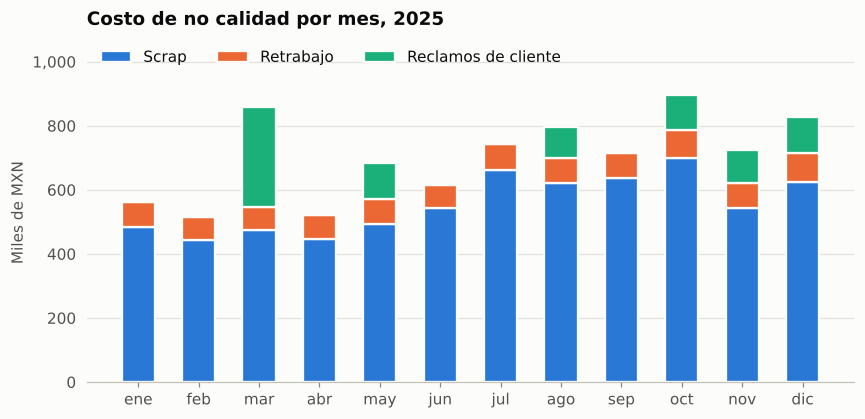

In [4]:
monthly = m.copq_by_month(prod, claims)
fig = plots.copq_mensual(monthly)
fig.savefig(FIGURES / "copq_mensual.png")

In [5]:
by_line = prod.groupby("linea").agg(proceso=("proceso", "first"), piezas=("piezas_producidas", "sum"),
                                   scrap=("piezas_scrap", "sum"), costo_scrap_mxn=("costo_scrap_mxn", "sum"))
by_line["tasa_scrap_%"] = 100 * by_line["scrap"] / by_line["piezas"]
by_line["%_del_costo_scrap"] = 100 * by_line["costo_scrap_mxn"] / by_line["costo_scrap_mxn"].sum()
by_line

,proceso,piezas,scrap,costo_scrap_mxn,tasa_scrap_%,%_del_costo_scrap
linea,,,,,,
L1,Estampado,2373442,45456,2054622,1.92,30.79
L2,Soldadura robotizada,702461,19882,3267178,2.83,48.96
L3,Soldadura manual,341406,9258,1351282,2.71,20.25


El scrap sube en la segunda mitad del año por dos razones:
- **Temporada de lluvias** (junio a octubre), que golpea a las líneas de soldadura.
- **Operadores nuevos en el turno nocturno**, que se acumulan de agosto a diciembre.

Los reclamos llegan en picos. L2, la soldadura robotizada, produce una quinta parte de las piezas pero concentra casi la mitad del costo de scrap: tiene la tasa más alta y sus piezas son caras.

## 3. ¿Qué defectos importan? Pareto por piezas frente a Pareto por costo

Un Pareto por conteo dirige el esfuerzo a los defectos *frecuentes*; uno por costo lo dirige a los *caros*. Aquí no coinciden.

,defecto,valor,pct_costo,pct_acum,pocos_vitales,pct_piezas
0,Porosidad,"2,026,874.00",26.94,26.94,True,17.11
1,Dimensional,"1,789,255.00",23.78,50.73,True,28.95
2,Falta de fusión,"1,219,964.00",16.22,66.95,True,4.96
3,Rebaba,"638,871.00",8.49,75.44,True,18.93
4,Perforación,"633,142.00",8.42,83.85,True,5.16
5,Grieta,"602,422.00",8.01,91.86,False,11.91
6,Daño superficial,"363,106.00",4.83,96.69,False,10.72
7,Socavado,"249,018.00",3.31,100.00,False,2.28


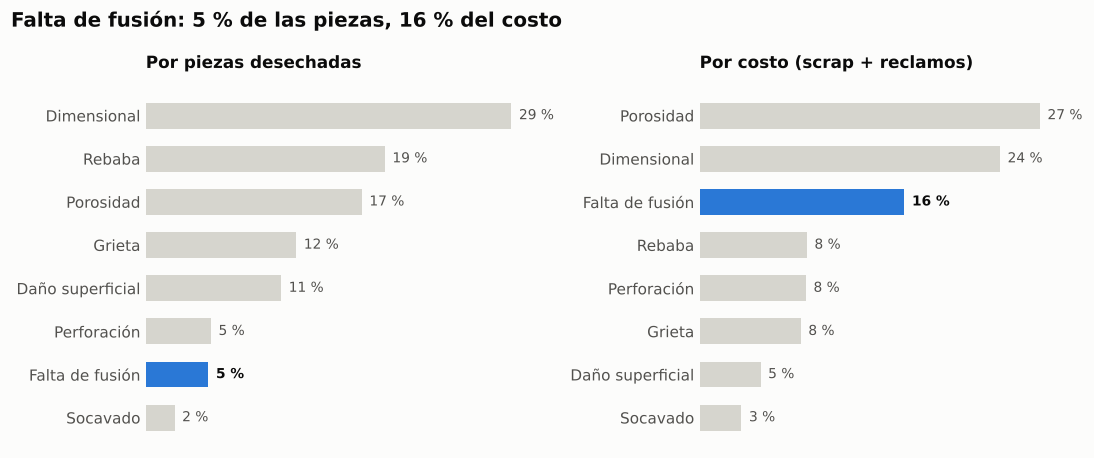

In [6]:
by_pieces = m.pareto(defects, prod, by="piezas")
by_cost = m.pareto(defects, prod, claims, by="costo")
fig = plots.pareto_doble(by_pieces, by_cost)
fig.savefig(FIGURES / "pareto_piezas_vs_costo.png")
by_cost.merge(by_pieces[["defecto", "pct"]], on="defecto", suffixes=("_costo", "_piezas"))

Al ordenar por costo cambian las prioridades:
- **Rebaba** (estampado) es el 2.º defecto más frecuente, pero vale poco porque las piezas estampadas son baratas.
- **Falta de fusión** sube del 7.º al 3.er lugar. Las piezas soldadas cuestan más, y como el defecto es interno, escapa a la inspección visual y termina en reclamos.

## 4. ¿El proceso está bajo control?

La carta p clásica supone variación puramente binomial. Con subgrupos grandes (miles de piezas al día) casi cualquier proceso real muestra **sobredispersión**, y la carta marca señales falsas a diario. La **carta p′ de Laney** (2002) amplía los límites con la variación real entre días (σ_z). Las reglas de Western Electric se aplican sobre la serie estandarizada.

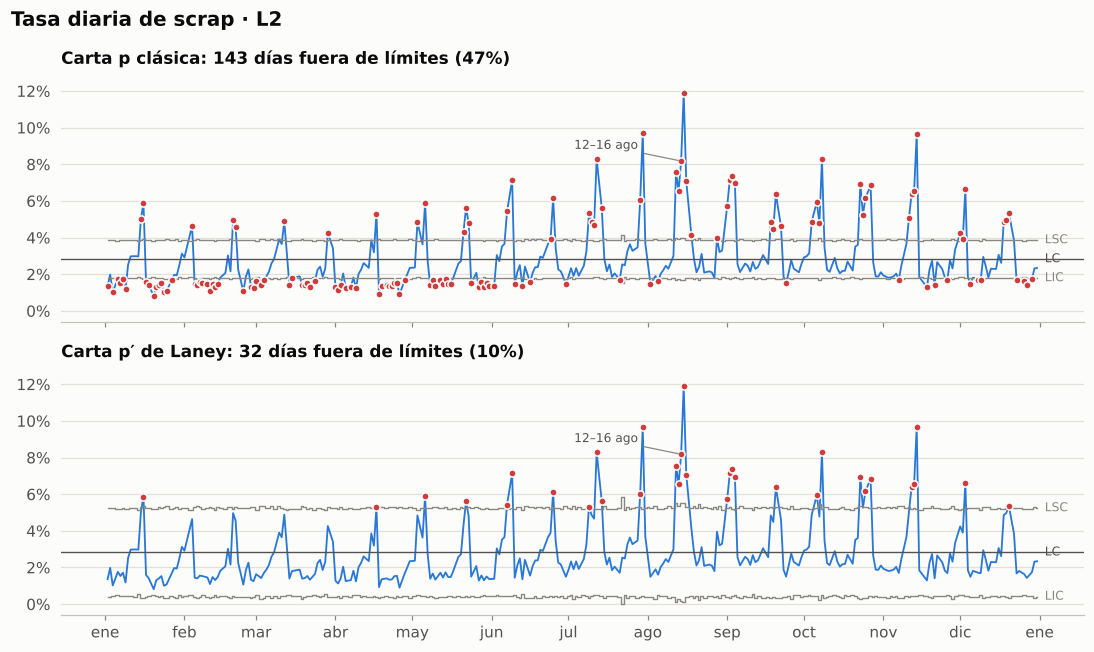

In [7]:
classic = m.p_chart(m.daily(prod, "L2"))
laney = m.p_chart(m.daily(prod, "L2"), laney=True)
fig = plots.carta_control(classic, laney, "L2", events=[(pd.Timestamp("2025-08-14"), "12–16 ago")])
fig.savefig(FIGURES / "carta_p_vs_laney_L2.png")

In [8]:
rows = {}
for line in ("L1", "L2", "L3"):
    c, l = m.p_chart(m.daily(prod, line)), m.p_chart(m.daily(prod, line), laney=True)
    rows[line] = {"σ_z (Laney)": l.attrs["sigma_z"], "Fuera de límites · p": int(c["regla_1"].sum()),
                  "Fuera de límites · p′": int(l["regla_1"].sum()), "Días con alguna regla · p′": int(l["senal"].sum())}
pd.DataFrame.from_dict(rows, orient="index").round(2)

,σ_z (Laney),Fuera de límites · p,Fuera de límites · p′,Días con alguna regla · p′
L1,2.32,56,9,34
L2,2.33,143,32,148
L3,1.19,26,12,117


Con la carta clásica, L2 parece fuera de control casi la mitad de los días, lo que en planta se traduce en alarmas que nadie atiende. La p′ deja **32 días fuera de límites**. Para saber qué tienen en común, se cruzan con las horas desde el mantenimiento y con el tipo de defecto:

In [9]:
l2 = prod[prod["linea"] == "L2"]
hours = l2.groupby("fecha")["horas_desde_mantto"].mean()
out = laney[laney["regla_1"]].assign(horas_desde_mantto=hours)
print(f"Días fuera de límites con más de 170 h desde el mantenimiento: {(out['horas_desde_mantto'] > 170).sum()} de {len(out)}")

grupo = pd.Series("Días normales", index=hours.index)
grupo[out.index] = "Fuera de límites (resto)"
grupo[out.index[(out.index >= "2025-08-12") & (out.index <= "2025-08-16")]] = "Fuera de límites · 12–16 ago"
mix = defects.merge(l2[["run_id", "fecha"]], on="run_id").assign(grupo=lambda d: d["fecha"].map(grupo))
firma = mix.pivot_table(index="grupo", columns="defecto", values="piezas", aggfunc="sum")
firma = 100 * firma.div(firma.sum(axis=1), axis=0)
firma["paro promedio (min)"] = l2.groupby(l2["fecha"].map(grupo))["paro_min"].mean()
firma.round(1)

Días fuera de límites con más de 170 h desde el mantenimiento: 32 de 32


defecto,Dimensional,Falta de fusión,Perforación,Porosidad,paro promedio (min)
grupo,,,,,
Días normales,26.00,9.70,20.10,44.20,17.80
Fuera de límites (resto),14.90,4.00,18.10,62.90,17.70
Fuera de límites · 12–16 ago,42.50,2.50,11.30,43.70,76.70


Los días fuera de límites tienen **dos firmas distintas**:
- **Desgaste:** pesa más la porosidad (63 % del scrap, contra 44 % en días normales), y todos ocurren después de unas 170 horas sin mantenimiento.
- **Falla de fixture** (12–16 de agosto): domina el defecto *dimensional* (43 % contra 26 %) y el paro promedio pasa de 18 a 77 minutos. Es una causa asignable distinta, de un solo evento.

Los dos problemas exigen acciones diferentes.

## 5. ¿Qué causa el scrap? Exploración

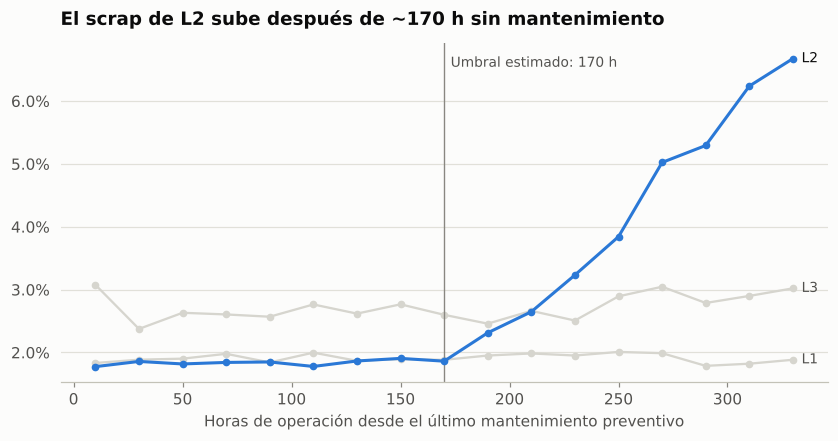

In [10]:
binned = m.rate_by_maintenance_hours(prod)
binned = binned[binned["corridas"] >= 10]
fig = plots.scrap_vs_mantenimiento(binned, threshold=170)
fig.savefig(FIGURES / "scrap_vs_mantenimiento.png")

En L1 y L3 la tasa no depende de las horas desde el mantenimiento; en L2 sube a partir de unas 170 horas. El 46 % de las corridas de L2 opera por encima de ese umbral, porque la planta aplica el mismo intervalo de 320 horas a las tres líneas.

In [11]:
night = prod[prod["turno"] == "Nocturno"].assign(con_nuevos=lambda d: d["operadores_nuevos"] > 0)
crew = m.scrap_rate(night, ["linea", "con_nuevos"]).unstack()
crew.columns = ["Sin operadores nuevos", "Con operadores nuevos"]
print("Tasa de scrap por turno (%):", (100 * m.scrap_rate(prod, "turno")).round(2).to_dict())
print("Altas del año por turno:", t["altas_operadores"].groupby("turno").size().to_dict())
(100 * crew).round(2)

Tasa de scrap por turno (%): {'Matutino': 1.95, 'Nocturno': 2.59, 'Vespertino': 2.01}
Altas del año por turno: {'Nocturno': 10}


,Sin operadores nuevos,Con operadores nuevos
linea,,
L1,2.07,2.25
L2,2.54,4.23
L3,2.61,5.17


In [12]:
l1 = prod[prod["linea"] == "L1"]
cracks = defects[defects["defecto"] == "Grieta"].merge(l1[["run_id", "proveedor_material"]], on="run_id")
supplier = pd.DataFrame({
    "% del material de L1": 100 * l1.groupby("proveedor_material")["piezas_producidas"].sum() / l1["piezas_producidas"].sum(),
    "% de las grietas": 100 * cracks.groupby("proveedor_material")["piezas"].sum() / cracks["piezas"].sum(),
    "tasa de grieta %": 100 * cracks.groupby("proveedor_material")["piezas"].sum() / l1.groupby("proveedor_material")["piezas_producidas"].sum(),
})
supplier.round(2)

,% del material de L1,% de las grietas,tasa de grieta %
proveedor_material,,,
A,53.38,36.65,0.26
B,31.67,21.63,0.26
C,14.95,41.72,1.04


In [13]:
welding = prod[prod["linea"] != "L1"]
por = defects[defects["defecto"] == "Porosidad"].merge(welding[["run_id", "fecha"]], on="run_id")
porosity = 100 * por.groupby(por["fecha"].dt.month)["piezas"].sum() / welding.groupby(welding["fecha"].dt.month)["piezas_producidas"].sum()
humidity = welding.groupby(welding["fecha"].dt.month)["humedad_rel_pct"].mean()
pd.DataFrame({"humedad media %": humidity, "tasa de porosidad %": porosity}).T.round(2)

fecha,1,2,3,4,5,6,7,8,9,10,11,12
humedad media %,50.22,46.19,43.58,46.81,53.08,68.86,72.10,74.64,75.96,68.99,60.01,54.16
tasa de porosidad %,0.80,0.73,0.69,0.61,0.94,1.36,1.78,1.53,1.91,1.71,1.34,1.20


Hallazgos de la exploración:
- **Turno nocturno:** 2.6 % de scrap contra 2.0 % en los turnos de día. Todas las altas del año entraron de noche, y en soldadura manual (L3) las noches *con* operadores nuevos casi duplican la tasa.
- **Proveedor C:** es el 15 % del material de L1 pero el 42 % de las grietas; su tasa de grieta es cuatro veces la de A y B.
- **Humedad:** la porosidad en soldadura pasa de 0.6–0.8 % en secas a 1.5–1.9 % en lluvias.

Todos estos factores se cruzan entre sí, así que el siguiente paso es separar sus efectos con un modelo.

## 6. Modelo explicativo: GLM binomial

Cada corrida es un conjunto de *n* piezas con *x* desechadas, así que se ajusta una regresión logística sobre proporciones (GLM binomial ponderado por *n*):
- **Errores estándar:** la escala cuasi-binomial (χ² de Pearson / gl) corrige la sobredispersión.
- **Variables:** cada una responde a una hipótesis de la exploración.
- **Umbral de mantenimiento:** se estima buscando el valor que minimiza la devianza.

In [14]:
thr, dev = md.find_threshold(prod)
print(f"Umbral con menor devianza: {thr} h")
dev.to_frame().T.round(0)

Umbral con menor devianza: 170 h


,80,90,100,110,120,130,140,150,160,170,180,190,200,210,220,230,240
devianza,"5,328.00","5,258.00","5,188.00","5,117.00","5,050.00","4,986.00","4,932.00","4,888.00","4,860.00","4,858.00","4,883.00","4,940.00","5,029.00","5,154.00","5,317.00","5,521.00","5,774.00"


Dispersión estimada (χ²/gl): 1.78


,odds_ratio,ic95_inf,ic95_sup,p_valor
Línea L2,0.90,0.87,0.93,0.00
Línea L3,1.22,1.18,1.26,0.00
Turno nocturno,1.13,1.10,1.16,0.00
Cambio de modelo,1.22,1.19,1.25,0.00
Operador nuevo · L1,1.10,1.06,1.14,0.00
Operador nuevo · L2,1.12,1.10,1.15,0.00
Operador nuevo · L3,1.34,1.31,1.37,0.00
+10 h sobre umbral de mantto · L2,1.10,1.09,1.10,0.00
Lote del proveedor C · L1,1.55,1.50,1.60,0.00
+10 pts de humedad · soldadura,1.16,1.14,1.17,0.00


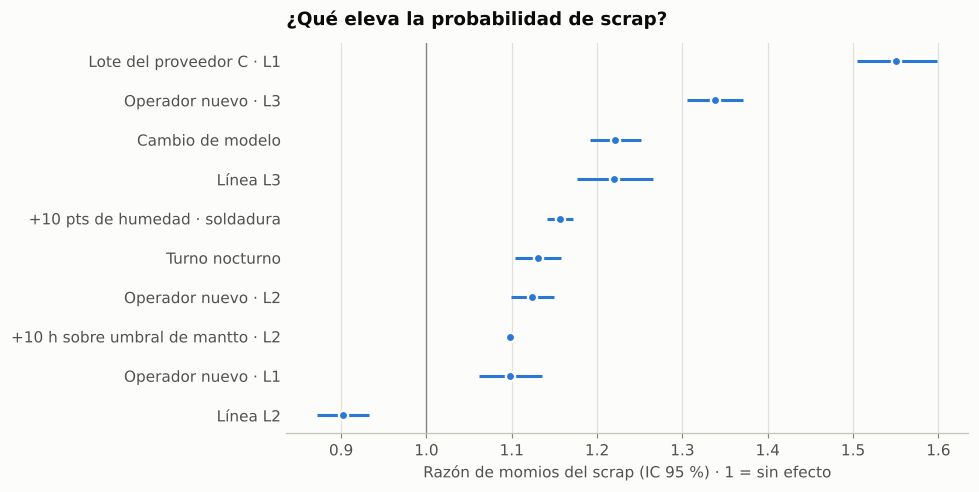

In [15]:
res = md.fit(prod, thr)
print(f"Dispersión estimada (χ²/gl): {res.scale:.2f}")
ors = md.odds_ratios(res)
fig = plots.odds_ratios(ors)
fig.savefig(FIGURES / "razones_de_momios.png")
ors.round(3)

Cómo leer las razones de momios: 1.34 en *Operador nuevo · L3* significa que cada operador nuevo en la cuadrilla de soldadura manual multiplica por 1.34 los momios de que una pieza sea scrap, con los demás factores constantes.

Con el efecto de los operadores nuevos ya en el modelo, **el turno nocturno conserva un efecto propio pequeño (≈ +13 %)**; el resto de su diferencia viene de la rotación.

**Validación fuera de muestra:** el modelo se entrena con enero a septiembre y se evalúa en octubre a diciembre, frente a un modelo base que solo usa el promedio de cada línea.

In [16]:
md.holdout(prod, threshold=thr).round(3).to_frame()

,error_absoluto_medio_pp
Modelo base (promedio por línea),1.18
GLM binomial,0.65


## 7. ¿Cuánto se puede ahorrar?

El modelo predice el scrap de cada corrida en dos escenarios, el actual y el que resultaría al aplicar cada palanca. La diferencia se valora a costo de material más conversión. La incertidumbre se propaga con 2,000 simulaciones de los coeficientes (β ~ Normal(β̂, Σ̂)).

**Supuestos** (`scrap_copq/config.py`):

| Palanca | Supuesto |
|---|---|
| Mantenimiento de L2 | Hacer el preventivo en el umbral cuesta 4,500 MXN por servicio adicional (consumibles y calibración) |
| Inducción por competencias | Cuesta 15,000 MXN por operador nuevo y cierra el 50 % de su brecha de desempeño |
| Lotes del proveedor C | C es 2 % más barato en material. Los reclamos por grieta se trazaron a lotes de C y se suman al ahorro |

Ahorro neto total (mediana): 1,228,540 MXN/año = 14.5% del COPQ


,piezas_evitadas,ahorro_bruto_p50,costo_anual,ahorro_neto_p50,ahorro_neto_p10,ahorro_neto_p90
palanca,,,,,,
Mantenimiento preventivo de L2 en el umbral,"6,893.00","1,111,336.00","84,466.00","1,026,870.00","995,948.00","1,055,954.00"
Inducción por competencias a operadores nuevos,"1,658.00","227,786.00","150,000.00","77,786.00","61,237.00","94,821.00"
Reasignar los lotes del proveedor C al A,"3,345.00","349,816.00","225,931.00","123,884.00","116,138.00","131,637.00"


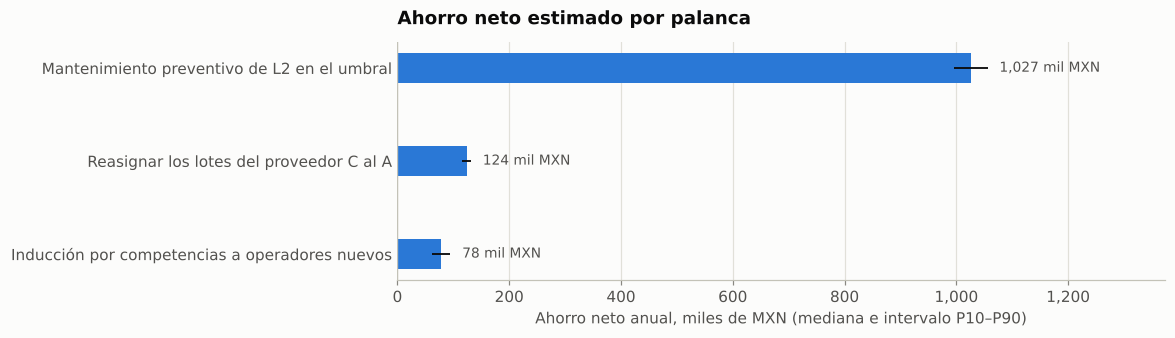

In [17]:
sav = md.simulate_savings(res, prod, t["catalogo_productos"], t["altas_operadores"], t["mantenimientos"],
                          claims, threshold=thr)
fig = plots.ahorro_por_palanca(sav, md.LEVERS)
fig.savefig(FIGURES / "ahorro_por_palanca.png")
table = sav.rename(index=md.LEVERS)[["piezas_evitadas", "ahorro_bruto_p50", "costo_anual", "ahorro_neto_p50",
                                     "ahorro_neto_p10", "ahorro_neto_p90"]]
print(f"Ahorro neto total (mediana): {sav['ahorro_neto_p50'].sum():,.0f} MXN/año "
      f"= {sav['ahorro_neto_p50'].sum() / k['copq_mxn']:.1%} del COPQ")
table.round(0)

¿Cada cuánto conviene el mantenimiento de L2? Acortar el intervalo evita scrap pero agrega servicios. La curva de ahorro neto es plana entre 160 y 190 horas; más allá de 200 horas el ahorro cae rápido.

Intervalo óptimo: 180 h · ahorro neto 1,030,225 MXN/año


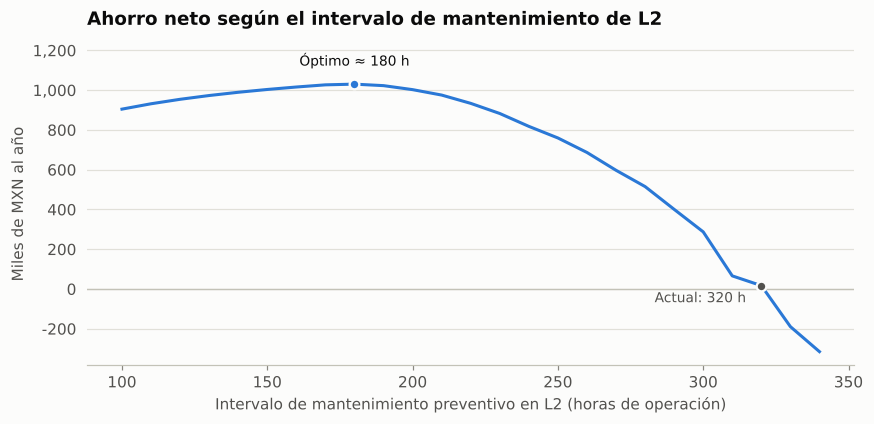

In [18]:
curve = md.maintenance_curve(res, prod, t["catalogo_productos"], t["mantenimientos"], threshold=thr)
fig = plots.curva_mantenimiento(curve, current=320)
fig.savefig(FIGURES / "curva_mantenimiento_L2.png")
print(f"Intervalo óptimo: {curve['ahorro_neto'].idxmax()} h · ahorro neto {curve['ahorro_neto'].max():,.0f} MXN/año")

In [19]:
full = md.simulate_savings(res, prod, t["catalogo_productos"], t["altas_operadores"], t["mantenimientos"],
                           claims, threshold=thr, gap_closed=1.0, levers=["induccion"]).loc["induccion"]
print(f"La inducción se paga si cierra al menos {full['costo_anual'] / full['ahorro_bruto_p50']:.0%} de la brecha.")

La inducción se paga si cierra al menos 37% de la brecha.


## 8. Recomendaciones

1. **Mantenimiento preventivo de L2 cada 170 a 180 horas** en lugar de 320. Es la palanca más rentable, con un ahorro neto cercano a 1 millón de MXN al año. Conviene validarla con un piloto de 8 semanas y una carta p′ antes y después.
2. **Gestionar al proveedor C por costo total, no por precio.** Su descuento del 2 % se pierde en scrap y reclamos. Antes de reasignar volumen, conviene exigirle certificado de dureza por lote e inspección de recibo, y medir el efecto.
3. **Inducción por competencias antes de asignar a un operador nuevo al turno nocturno**, sobre todo en soldadura manual. El ahorro en scrap es modesto, pero la falta de fusión, que genera la mayoría de los reclamos, también depende de la habilidad del soldador.
4. **Plan de humedad en temporada de lluvias** para la soldadura: almacenamiento del alambre y control del gas. No se cuantificó porque falta el costo de la medida.
5. **Cartas p′ de Laney en lugar de p clásicas** para el monitoreo diario, con reglas de reacción ligadas a la firma del defecto.

## Limitaciones

- **Datos sintéticos.** Los efectos se sembraron a propósito para demostrar el método. En una planta real habría que validar las causas en piso, por ejemplo con un 5 por qué o un Ishikawa por hallazgo.
- **Modelo observacional.** Las palancas asumen que el efecto estimado es causal. Un piloto controlado es la prueba definitiva.
- **Costos.** Los de mantenimiento y capacitación son supuestos y deben reemplazarse con datos de la planta.